# Lunar rover magnetometry of magnetized bedrock

Narrett, Zareck, Weiss & Hoffman, *Lunar Rover Magnetometry: Recovering Paleofield Intensity and Direction
From Magnetized Bedrock*, Planetary Science Journal (in preparation).

Part 1 builds the isolated-outcrop forward model and inverts it. Part 2 redraws the figures and recomputes
every number quoted in the paper from the stored results in `results/`.

**`RERUN` (first code cell) decides whether anything is recomputed.** With the default `RERUN = False` the notebook
draws no random numbers and runs no inversions: Part 1 builds the forward model (deterministic, a few seconds) and
reads its noisy-data results from `results/`, and Part 2 reads `results/`. Setting `RERUN = True` (or starting Jupyter
with `LUNAR_RERUN=1`) makes Part 1 draw the noise and run the inversions, checks them against the stored results, and
enables the final section, which regenerates every stored result (about 3.5 to 4 hours, overwriting `results/`).

In [1]:
import os, sys, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

import discretize
from simpeg import maps
from simpeg.potential_fields import magnetics as mag

ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd()
assert os.path.isdir(os.path.join(ROOT, "results")), "start Jupyter in the repository or its notebook/ folder"
sys.path[:0] = [os.path.join(ROOT, "engine"), os.path.join(ROOT, "notebook")]
from inversion_helpers import seed_for
from paper_numbers import numbers, count, J

# RERUN = False (default): load the stored results from results/; draw no noise and run no inversions.
# RERUN = True: Part 1 draws the noise and runs the inversions, and the last section regenerates results/.
# Set it here, or start Jupyter with the environment variable LUNAR_RERUN=1.
RERUN = os.environ.get("LUNAR_RERUN", "") == "1"
print("RERUN =", RERUN)


def figure(name, width=900):
    r = subprocess.run([sys.executable, f"{name}.py"], cwd=os.path.join(ROOT, "figures", "scripts"),
                       capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stderr)
    display(Image(filename=os.path.join(ROOT, "figures", "output", f"{name}.png"), width=width))

RERUN = False


# Part 1: forward model and inversion

## geologic setup

A 4 x 4 x 1 m outcrop on non-magnetic ground, uniformly magnetized at the reference magnetization
$M_\mathrm{ref} = 2.4 \times 10^{-3}$ A/m, pointing down ($-\hat z$). SimPEG conventions: right-handed,
$z$ up, SI units.

In [2]:
M_ref = 2.4e-3                                  # A/m
M_true = M_ref * np.array([0.0, 0.0, -1.0])
sigma_B = 0.5                                   # nT per axis, 1-sigma

## survey

Sensor 0.5 m above the ground, 1 m outside the outcrop faces, one measurement per centimeter. The drive-around
is a closed loop starting and ending at (-3, -3) m; the drive-by is a straight pass along y = -3 m from x = -8 to 8 m.

In [3]:
z = 0.5
t = np.linspace(-3.0, 3.0, 600)
c = np.zeros_like(t)
loop = np.vstack([np.c_[t, c - 3], np.c_[c + 3, t], np.c_[-t, c + 3], np.c_[c - 3, -t][:-1]])
x = np.linspace(-8.0, 8.0, 1601)

surveys = {
    "drive-around": np.c_[loop, np.full(len(loop), z)],
    "drive-by": np.c_[x, np.full_like(x, -3.0), np.full_like(x, z)],
}
for name, xyz in surveys.items():
    print(f"{name:12s} {len(xyz)} measurements")

drive-around 2399 measurements
drive-by     1601 measurements


## forward simulation

One mesh cell holds the whole outcrop, so the field is the exact field of a uniformly magnetized prism.
The source amplitude is set so the model is the magnetization vector in A/m (there is no induced part).

In [4]:
mesh = discretize.TensorMesh([[4.0], [4.0], [1.0]], origin=[-2.0, -2.0, 0.0])

def sensitivity(xyz):
    rx = mag.receivers.Point(xyz, components=["bx", "by", "bz"])
    src = mag.sources.UniformBackgroundField(receiver_list=[rx], amplitude=4e-7 * np.pi * 1e9, inclination=90.0, declination=0.0)
    sim = mag.simulation.Simulation3DIntegral(mesh, survey=mag.survey.Survey(src), chiMap=maps.IdentityMap(nP=3),
                                              model_type="vector", store_sensitivities="ram")
    return sim.G        # (3 x measurements) x 3: (Mx, My, Mz) in A/m -> (bx, by, bz) in nT

G = {name: sensitivity(xyz) for name, xyz in surveys.items()}
d_clean = {name: G[name] @ M_true for name in surveys}
for name, d in d_clean.items():
    print(f"{name:12s} peak outcrop field {np.linalg.norm(d.reshape(-1, 3), axis=1).max():.2f} nT")

drive-around peak outcrop field 0.25 nT
drive-by     peak outcrop field 0.25 nT


## synthetic data

With `RERUN = True`, one noise draw (seed 0) is added to the drive-around data. With `RERUN = False` no noise is drawn:
the plot shows the noise-free field and the single-draw result below is read from `results/notebook/`.

RERUN = False: no noise drawn; showing the noise-free outcrop field.


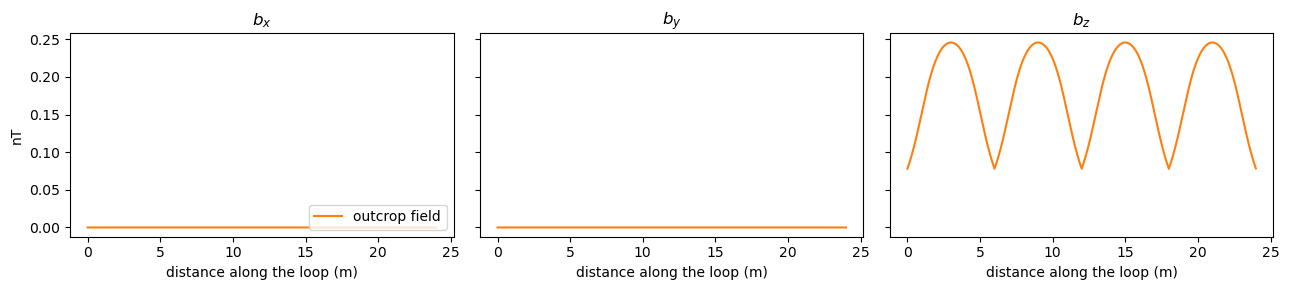

In [5]:
s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(surveys["drive-around"][:, :2], axis=0), axis=1))]

if RERUN:
    rng = np.random.default_rng(0)
    d_obs = d_clean["drive-around"] + rng.normal(0.0, sigma_B, d_clean["drive-around"].size)
else:
    d_obs = None
    print("RERUN = False: no noise drawn; showing the noise-free outcrop field.")

fig, ax = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for i, comp in enumerate("xyz"):
    if d_obs is not None:
        ax[i].plot(s, d_obs[i::3], ".", ms=1, color="0.7", label="with noise")
    ax[i].plot(s, d_clean["drive-around"][i::3], color="C1", label="outcrop field")
    ax[i].set_title(f"$b_{comp}$")
    ax[i].set_xlabel("distance along the loop (m)")
ax[0].set_ylabel("nT")
ax[0].legend(loc="lower right", markerscale=8)
plt.tight_layout()

## inversion

With the outcrop's shape and position known from rover imaging, the only unknowns are the three components of
its magnetization, so the inversion is a linear least-squares problem (Section 3.4). The noise is the same on
every axis, so the data weights cancel.

In [6]:
def invert(G, d):
    return np.linalg.solve(G.T @ G, G.T @ d)

def errors(M_rec, M_true):
    cos = M_rec @ M_true / (np.linalg.norm(M_rec, axis=-1) * np.linalg.norm(M_true))
    direction = np.degrees(np.arccos(np.clip(cos, -1, 1)))
    intensity = 100 * np.abs(np.linalg.norm(M_rec, axis=-1) - np.linalg.norm(M_true)) / np.linalg.norm(M_true)
    return direction, intensity

with open(os.path.join(ROOT, "results", "notebook", "part1_single_draw.json")) as f:
    single = json.load(f)                  # the same draw (seed 0), stored

if RERUN:
    M_rec = invert(G["drive-around"], d_obs)
    direction, intensity = errors(M_rec, M_true)
    assert np.allclose(M_rec, single["M_rec_A_per_m"], rtol=1e-6, atol=1e-12), "differs from results/notebook/"
else:
    print("RERUN = False: stored single-draw result from results/notebook/part1_single_draw.json")
    M_rec, direction, intensity = np.array(single["M_rec_A_per_m"]), single["dir_err_deg"], single["dM_abs_pct"]
print(f"recovered M = {np.round(M_rec * 1e3, 3)} mA/m (true {M_true * 1e3} mA/m)")
print(f"direction error {direction:.1f} deg, intensity error {intensity:.1f}%")

RERUN = False: stored single-draw result from results/notebook/part1_single_draw.json
recovered M = [-0.098  0.176 -2.569] mA/m (true [ 0.   0.  -2.4] mA/m)
direction error 4.5 deg, intensity error 7.4%


## 1000 noise draws

The paper's headline numbers (Section 4.2) are medians over 1000 noise draws. The random seeds are the ones the
analysis scripts use, so these match the stored results exactly. With `RERUN = False` the medians are read from
`results/analysis/a02_isolated_outcrop_paper_geometry.json`; with `RERUN = True` the 1000 draws are made and inverted
here and printed next to the stored values.

In [7]:
stored = J("a02_isolated_outcrop_paper_geometry.json")["baseline"]
for name in surveys:
    key = name.replace("-", "_")
    s_dir, s_dm = stored[key]["dir_err_deg"]["median"], stored[key]["dM_abs_pct"]["median"]
    if RERUN:
        rng = np.random.default_rng(seed_for(f"a02:base:{key}"))
        D = d_clean[name] + rng.normal(0.0, sigma_B, (1000, d_clean[name].size))
        direction, intensity = errors(invert(G[name], D.T).T, M_true)
        print(f"{name:12s} median direction error {np.median(direction):.1f} deg (stored {s_dir:.1f}), "
              f"intensity error {np.median(intensity):.1f}% (stored {s_dm:.1f})")
    else:
        print(f"{name:12s} stored median direction error {s_dir:.1f} deg, intensity error {s_dm:.1f}% "
              "(1000 draws; RERUN = False, none redrawn)")

drive-around stored median direction error 3.0 deg, intensity error 3.7% (1000 draws; RERUN = False, none redrawn)
drive-by     stored median direction error 6.6 deg, intensity error 7.3% (1000 draws; RERUN = False, none redrawn)


# Part 2: figures and numbers

Each section redraws its figures and prints every number quoted in it, recomputed from `results/`, next to the
sentence it appears in. A number that does not match the paper is flagged.

## Figures 1-3: survey geometries

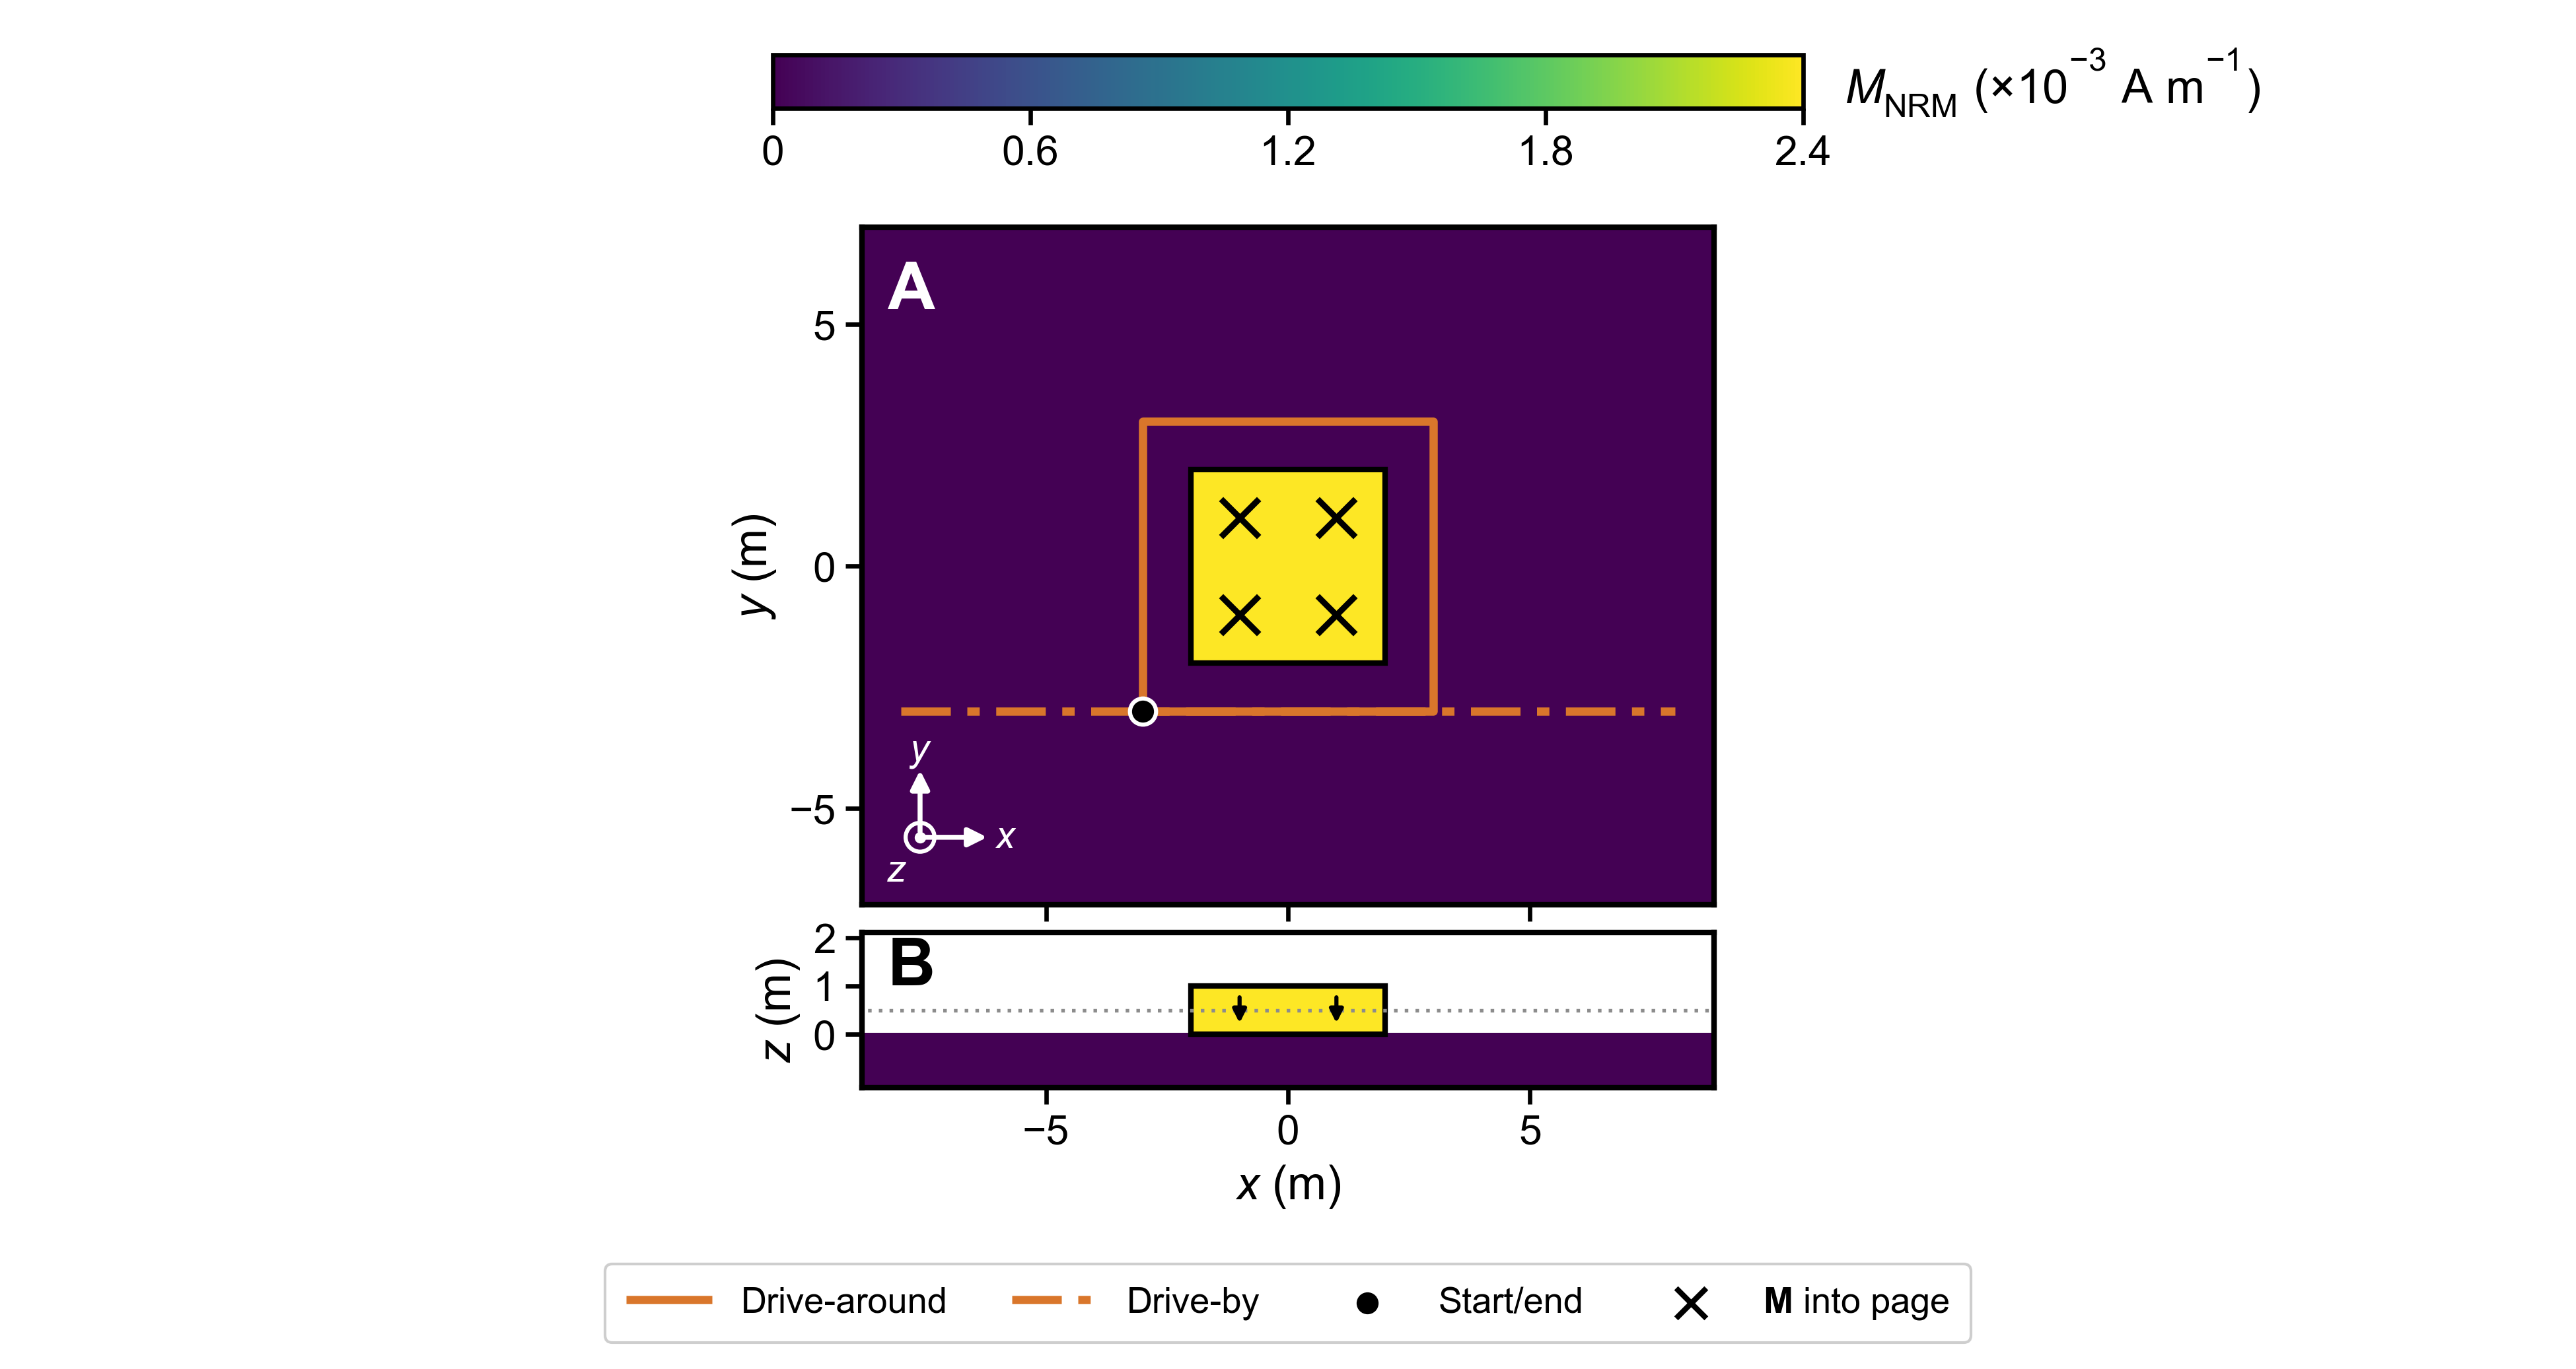

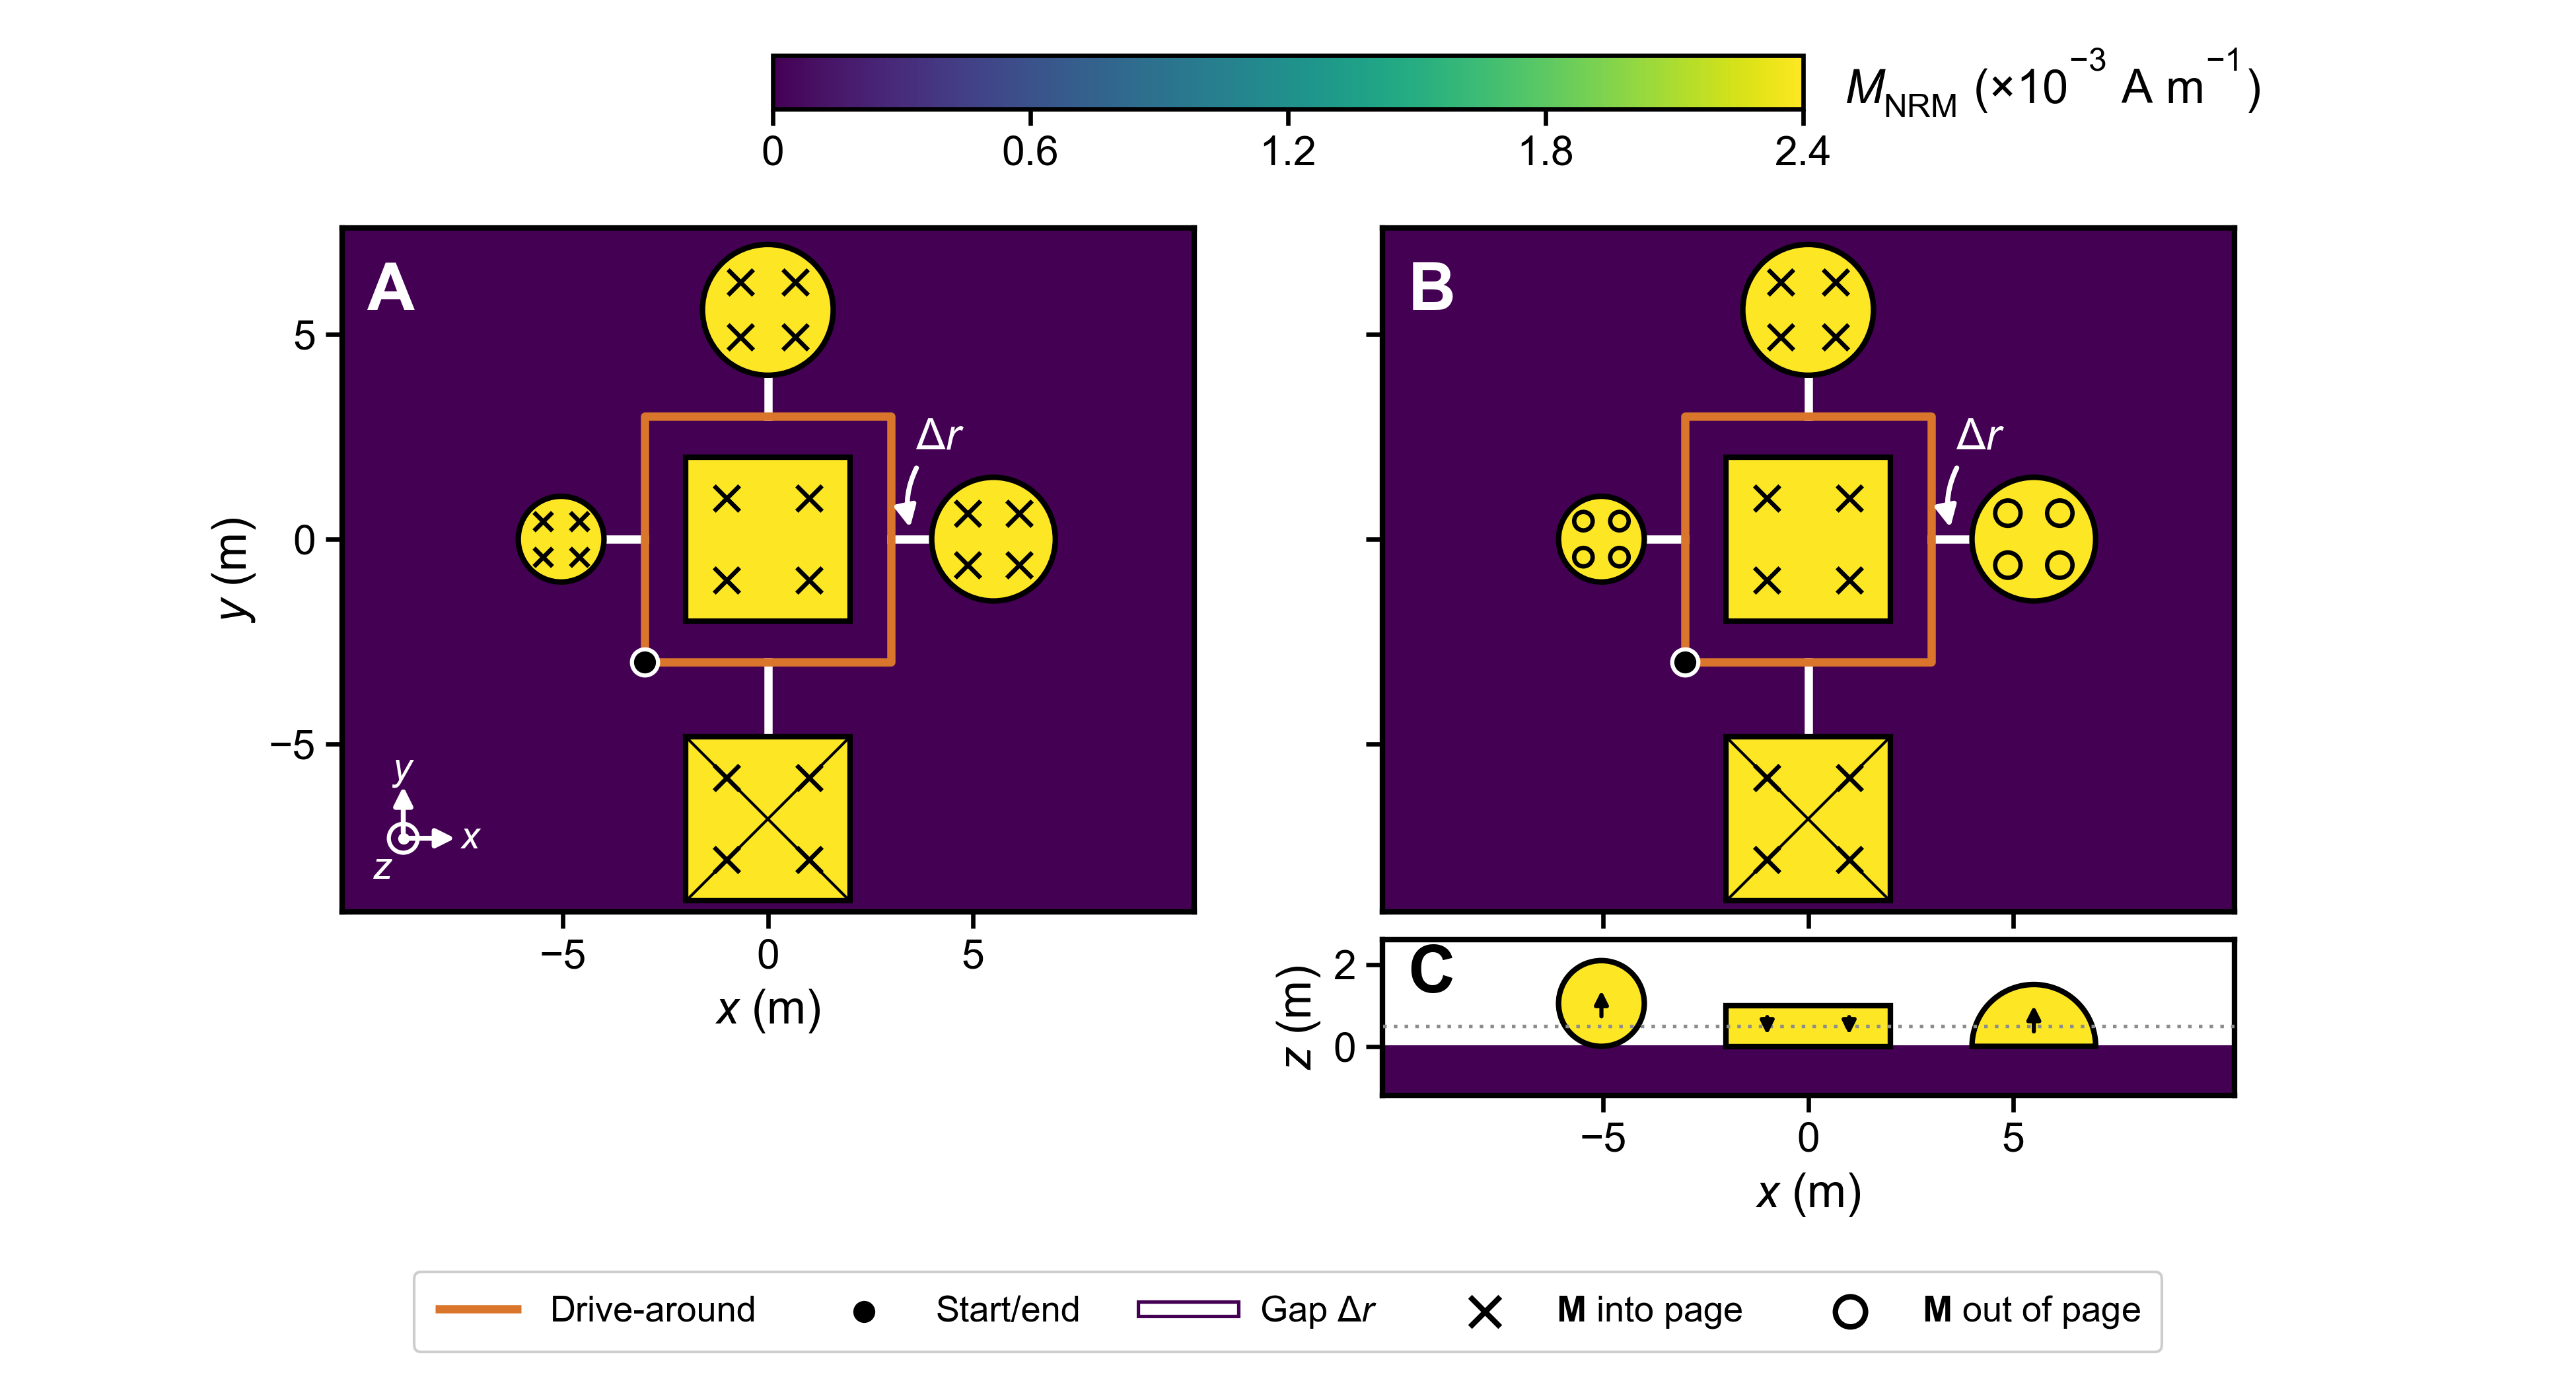

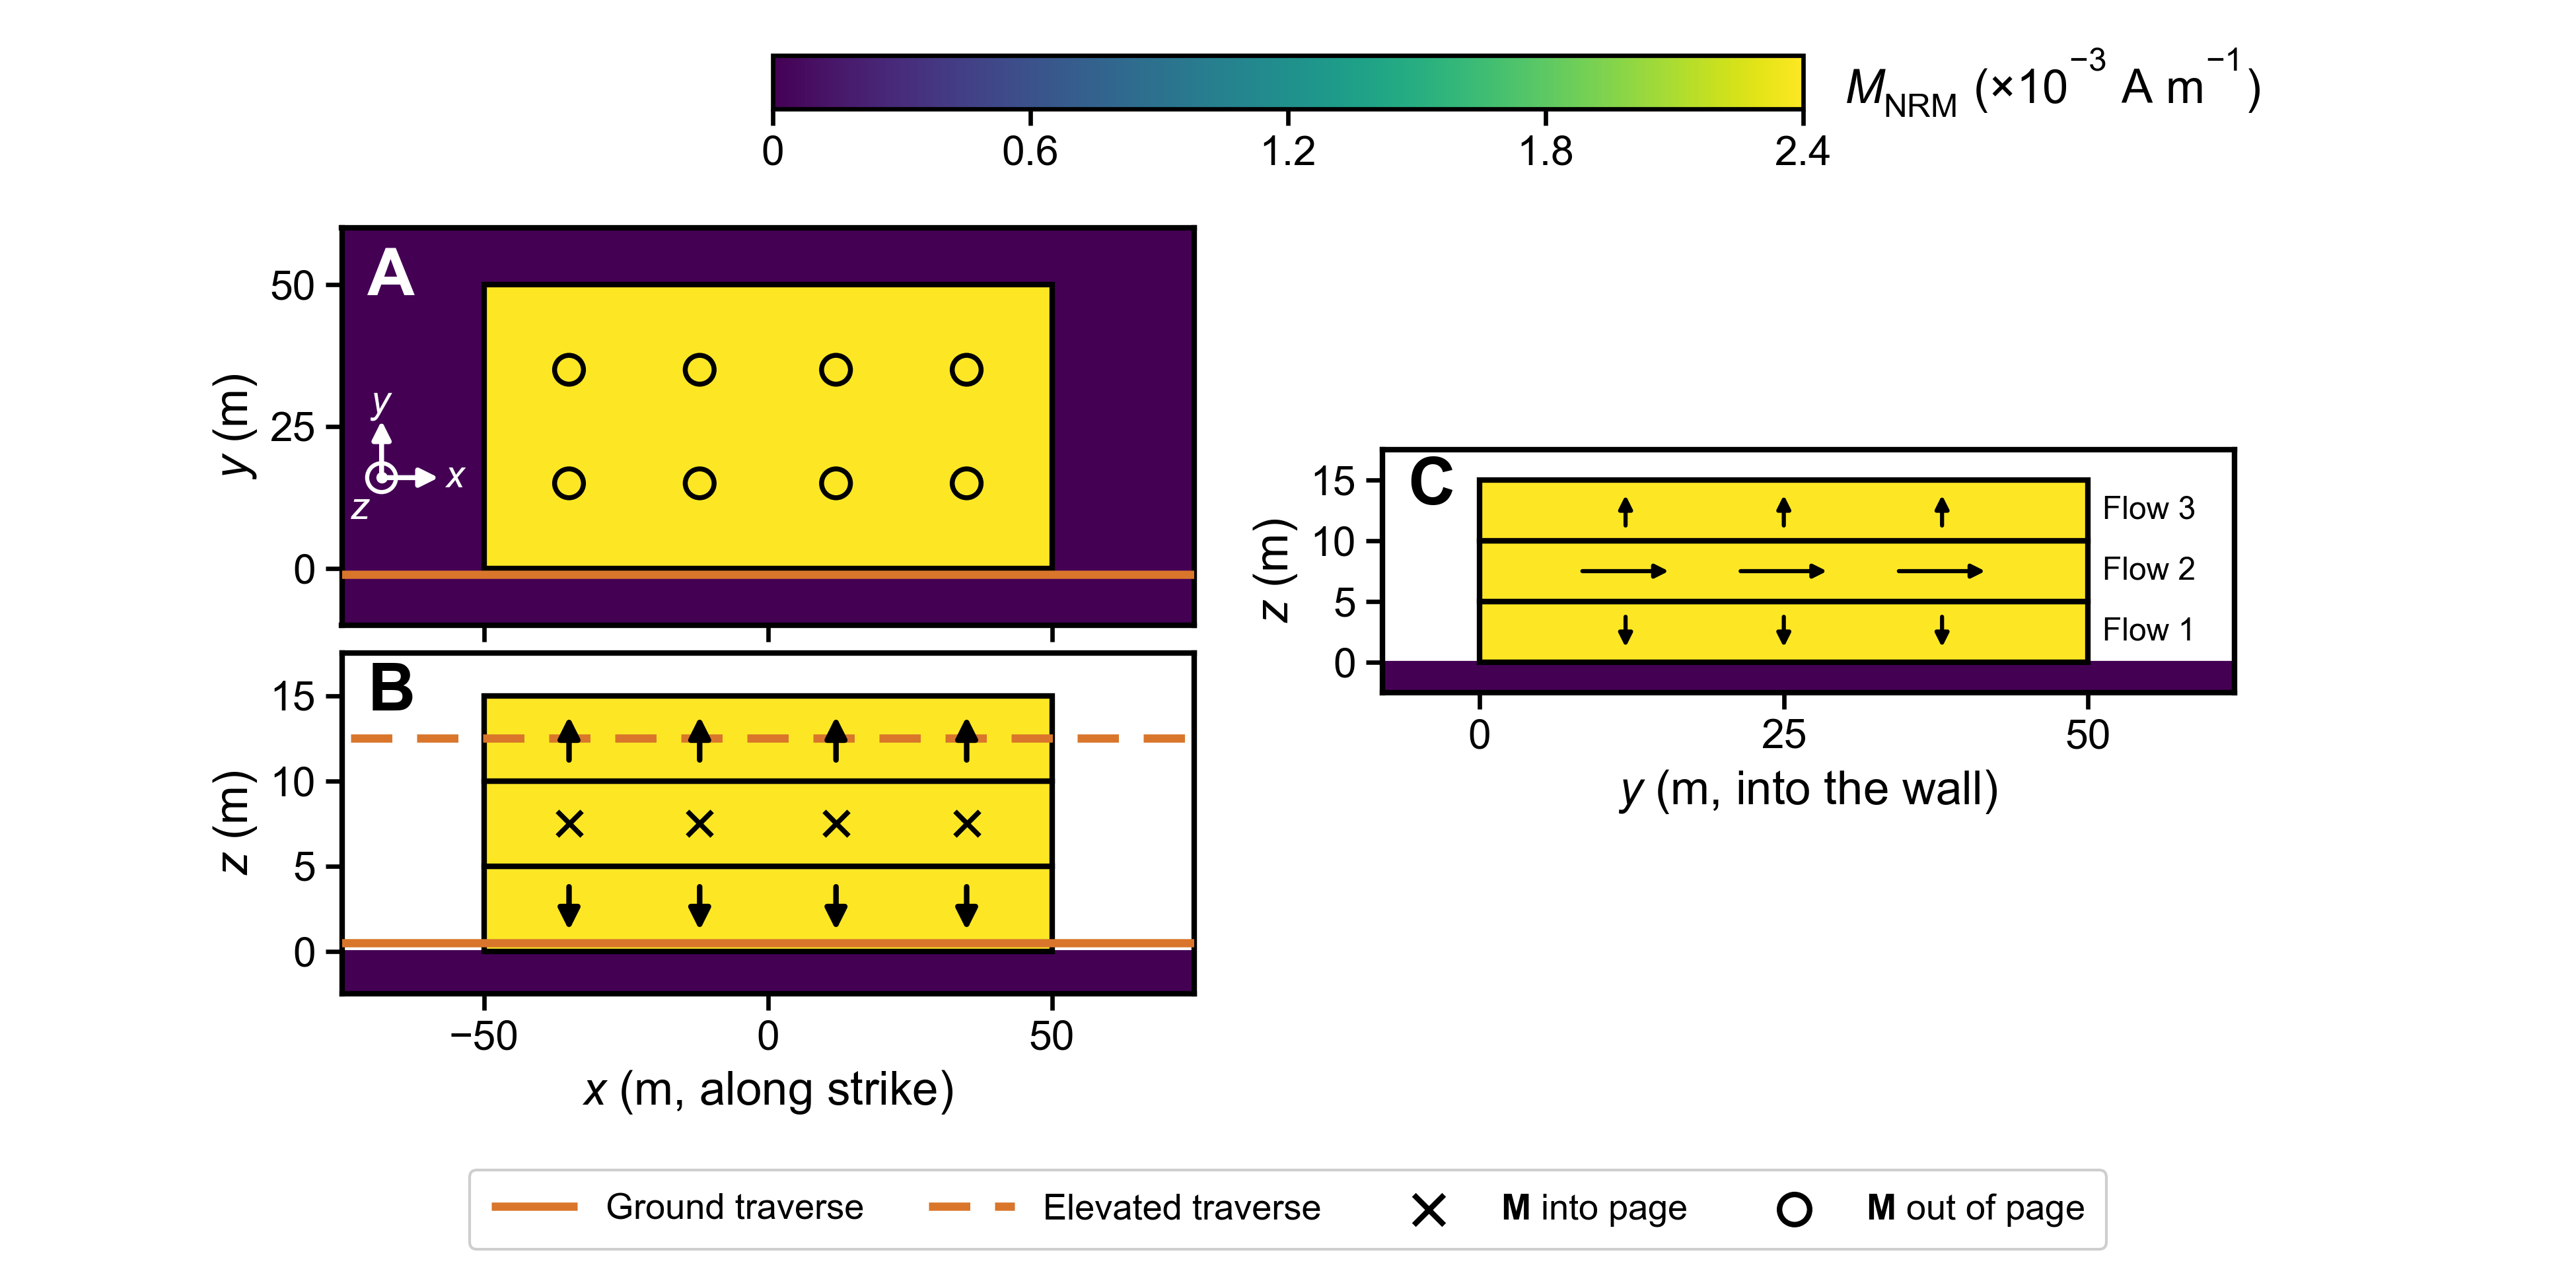

In [8]:
figure("fig01_isolated_outcrop_geometry")
figure("fig02_skatepark_geometry")
figure("fig03_three_layer_geometry")

## Abstract

In [9]:
numbers("Abstract")


Abstract
       30  …traverse recovers the lowest flow to ∼4° but the upper two only to ∼30°; adding a traverse 6.4–13 m up the wall recovers all three to <5° if the …
        5  …we derive, with drift ≲0.01 nT rms, loops driven both ways and tilt fitted, brings it to 3–5° with loops centered to 0.1 m and burial ≤0.5 m, or with the buried …


## Section 3: modeling framework

In [10]:
numbers("3.2")
numbers("3.3")
numbers("3.5")


Section 3.2. Magnetic Field Contributions: Signals of Interest and Sources of Noise
     0.25  …the isolated outcrop of Section 3.3.3 produces a peak field of 0.25 nT along a traverse 1 m from its faces, and all results in Section 4 use …

Section 3.3. Forward Models
    0.003  …5-m-thick slab that extends ±1.2 km laterally, which produces a field of 0.003 nT root-mean-square (rms; 0.65% of σ_B and ∼3% of the outcrop's field) along the …
     0.65  …±1.2 km laterally, which produces a field of 0.003 nT root-mean-square (rms; 0.65% of σ_B and ∼3% of the outcrop's field) along the drive-around traverse.
      3.4  The slab changes the mean recovered direction error from 3.3° to 3.4° and the mean intensity error from -0.1% to -2.9% (400 inversions), so …
     -2.9  …error from 3.3° to 3.4° and the mean intensity error from -0.1% to -2.9% (400 inversions), so even a weak coherent field (∼3% of the outcrop's) changes the …
        3  …which produces a field of 0.003 nT root-mean-square (rm

## Section 4.1: inversion approach selection (Table 2)

In [11]:
numbers("4.1")


Section 4.1. Inversion Approach Selection
     0.27  Over 20 noise draws, the direction errors of the volume-averaged magnetization are 0.27 ± 0.13° (mean ±1-σ) for the parametric inversion, 1.24 ± 1.03° for …
     1.24  …are 0.27 ± 0.13° (mean ±1-σ) for the parametric inversion, 1.24 ± 1.03° for the Cartesian inversion, and 3.10 ± 1.66° for the spherical …
     3.10  …for the parametric inversion, 1.24 ± 1.03° for the Cartesian inversion, and 3.10 ± 1.66° for the spherical inversion, and the mean intensity errors are -0.3%, -8.9%, …
      4.6  …source geometry known, the parametric inversion recovered the magnetization direction 4.6 ± 1.0 times more accurately than the Cartesian voxel inversion and 11.6 ± 1.8 times more …
     11.6  …direction 4.6 ± 1.0 times more accurately than the Cartesian voxel inversion and 11.6 ± 1.8 times more accurately than the spherical voxel inversion (Table …
     -3.1  …the spherical inversion, and the mean intensity errors are -0.3%, -8.9%, and -3.1%, 

## Section 4.2: isolated outcrop (Figures 4 and 5, Table 3)

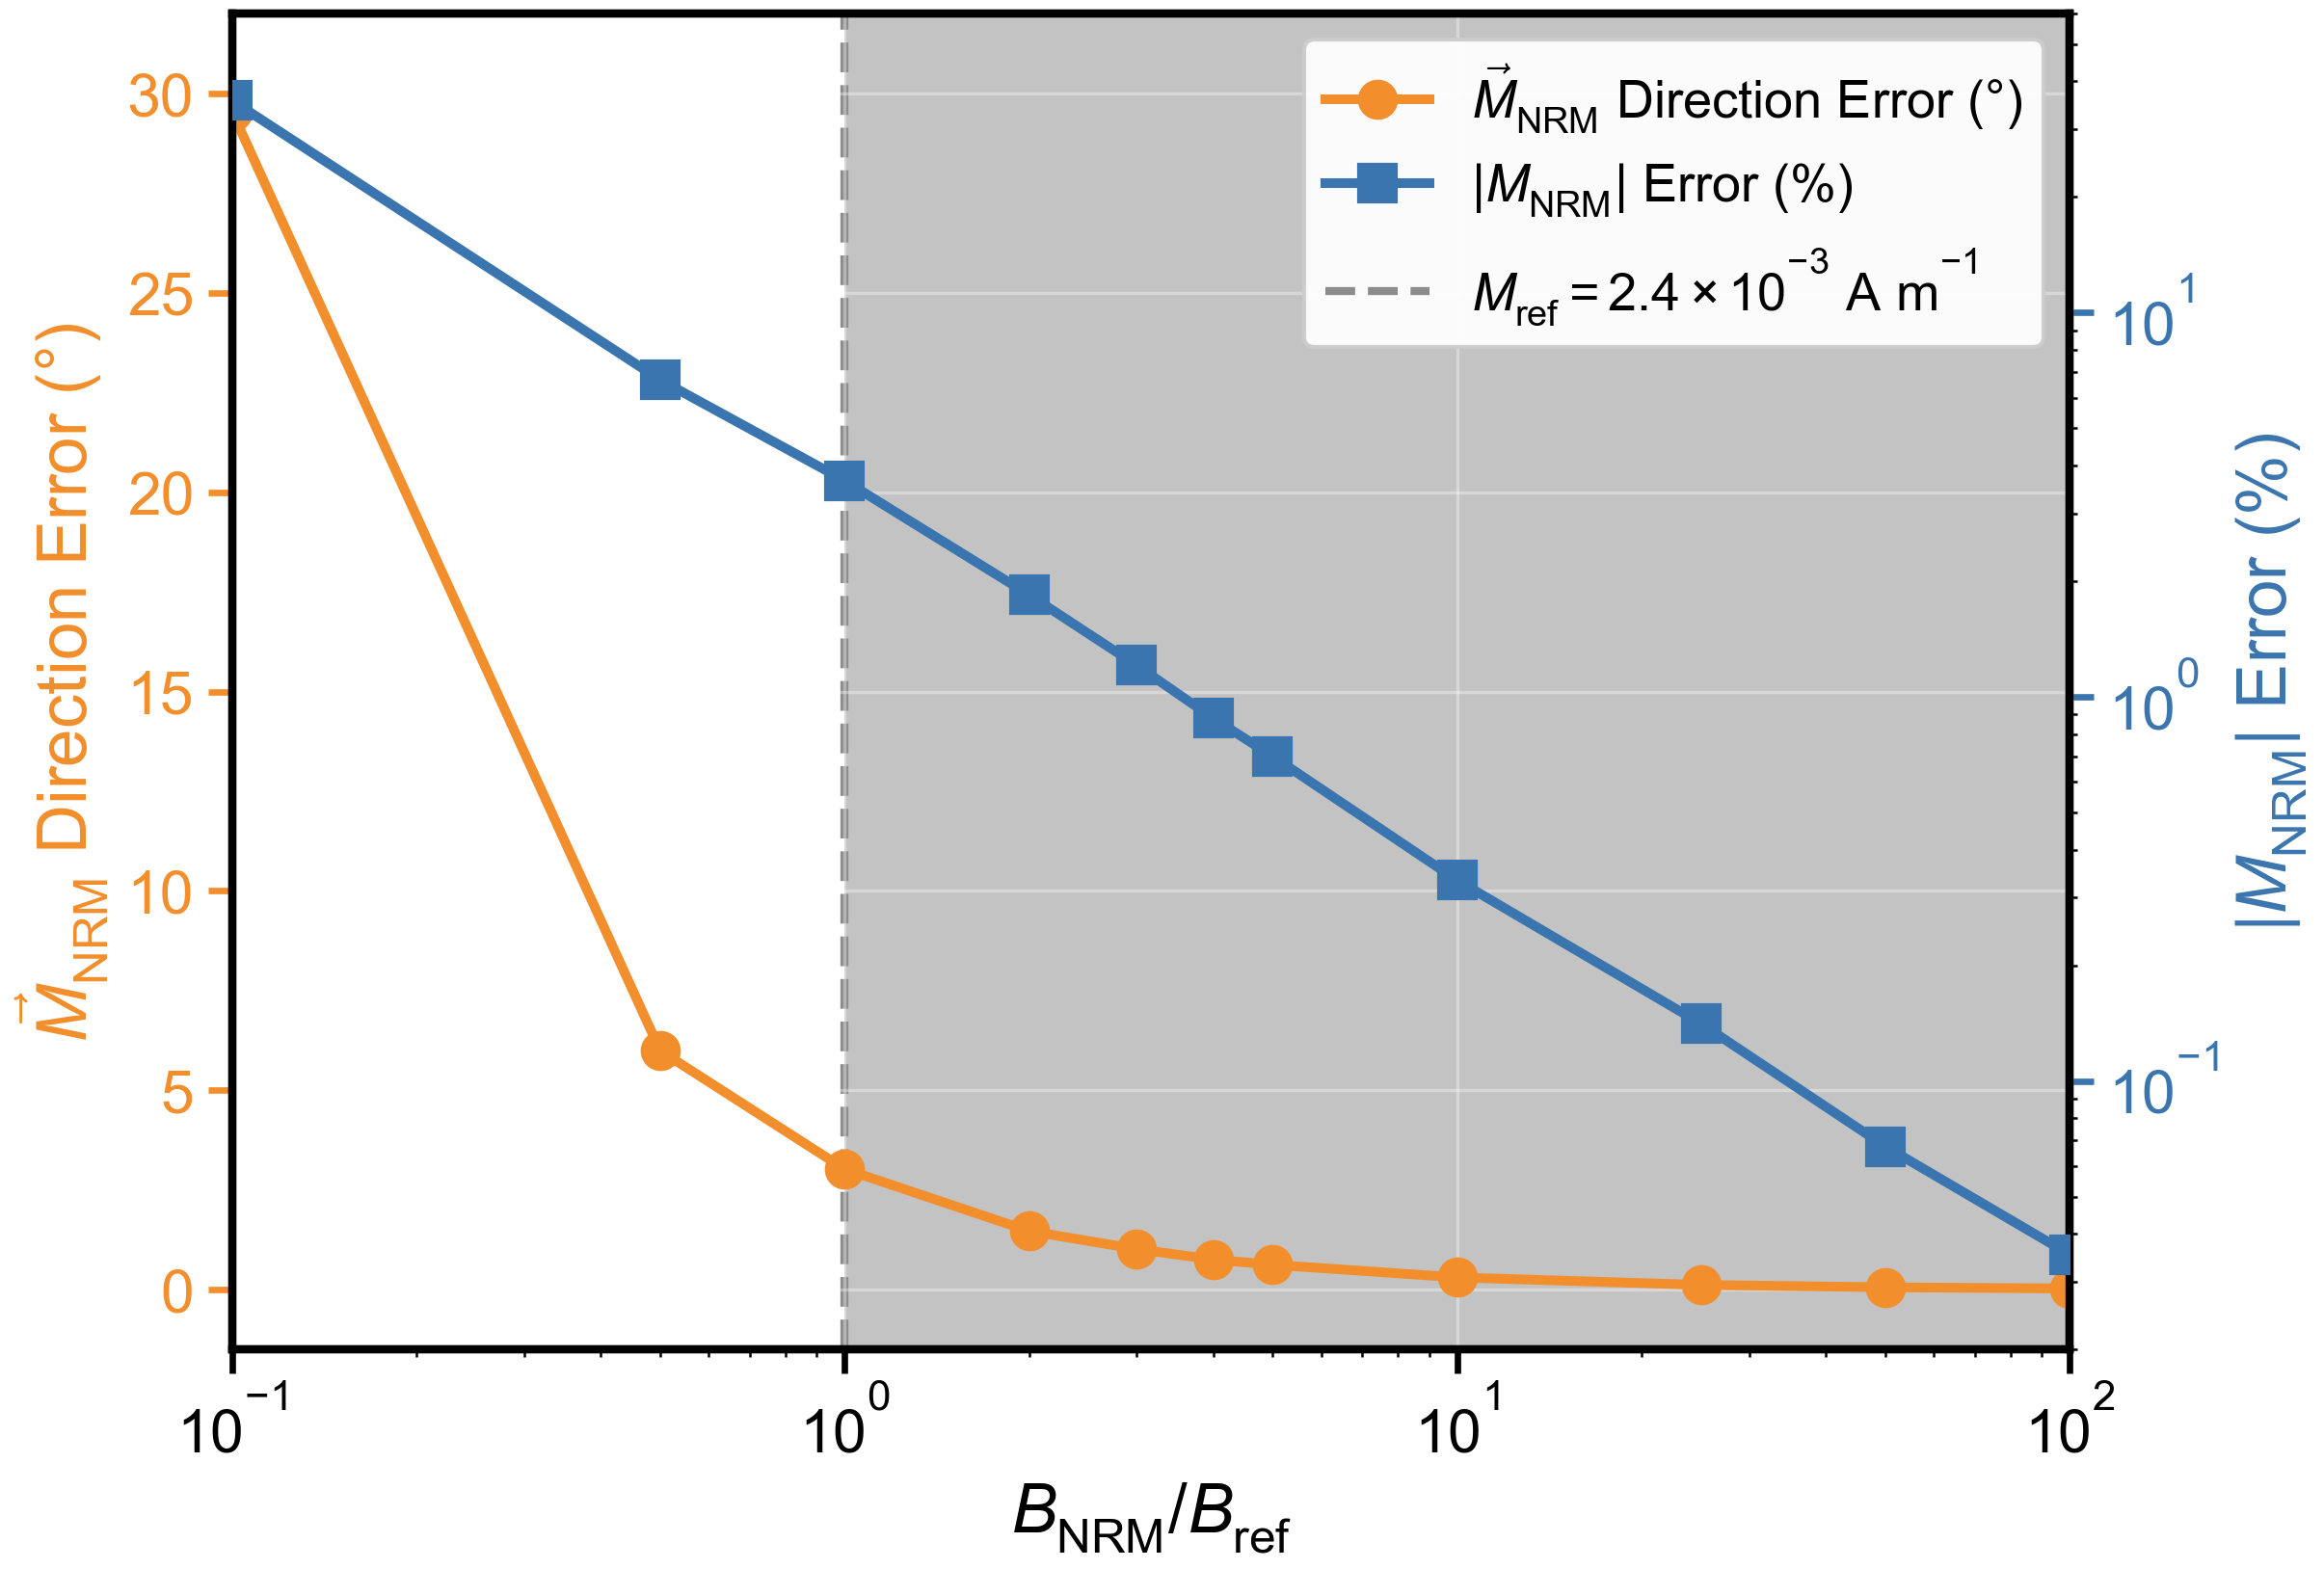

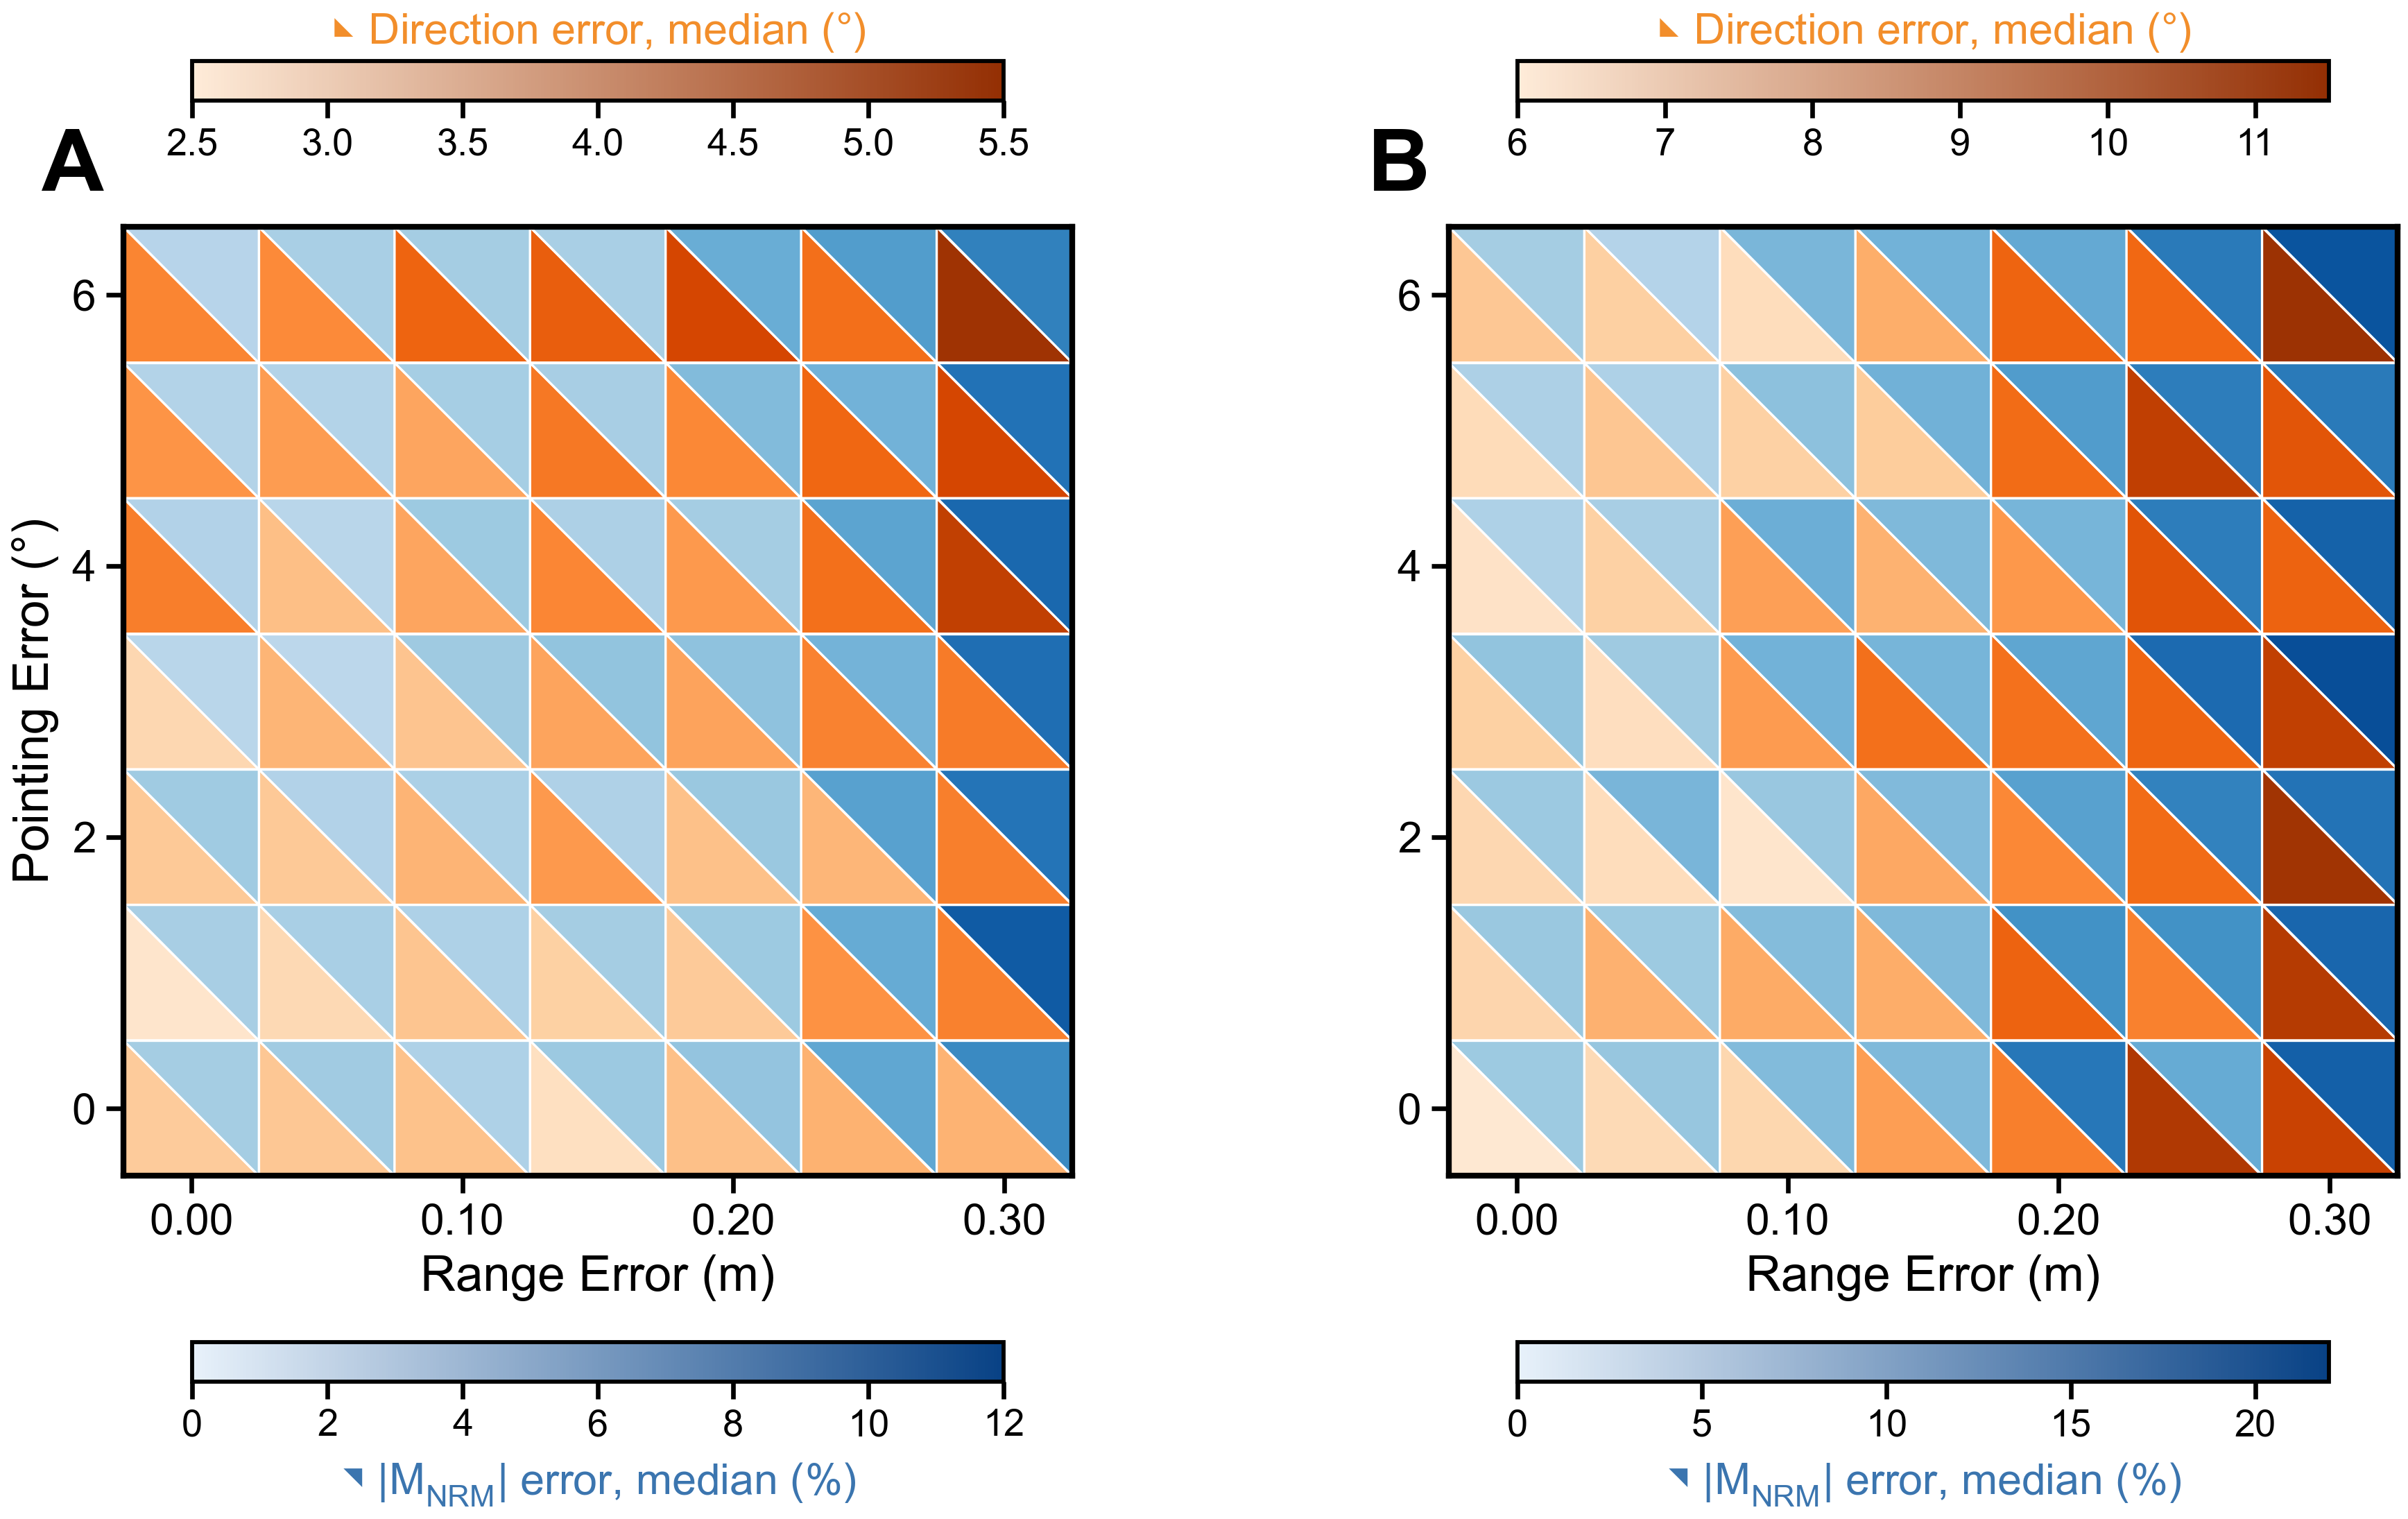


Section 4.2. Isolated Outcrop
      3.0  …The drive-around survey recovers the isolated outcrop's NRM direction to 3.0° and its intensity to 3.7% (medians of 1000 inversions; K = 1 parametric inversion; …
      3.7  …recovers the isolated outcrop's NRM direction to 3.0° and its intensity to 3.7% (medians of 1000 inversions; K = 1 parametric inversion; Section 3.3.3), with …
      3.2  …inversions; K = 1 parametric inversion; Section 3.3.3), with a mean direction error of 3.2° and a 95th percentile of 6.1°.
      6.1  …Section 3.3.3), with a mean direction error of 3.2° and a 95th percentile of 6.1°.
    +0.06  The intensity error has almost no bias (mean signed error +0.06%) and a standard deviation of 5.5%.
      5.5  The intensity error has almost no bias (mean signed error +0.06%) and a standard deviation of 5.5%.
     2399  …half of σ_B; the recovery instead relies on fitting three unknowns to 7197 data (2399 three-component measurements), over which the noise averages down.
     

In [12]:
figure("fig04_detection_envelope", 600)
figure("fig05_lidar_sensitivity")
numbers("4.2")

## Section 4.3: skate park (Figure 6)

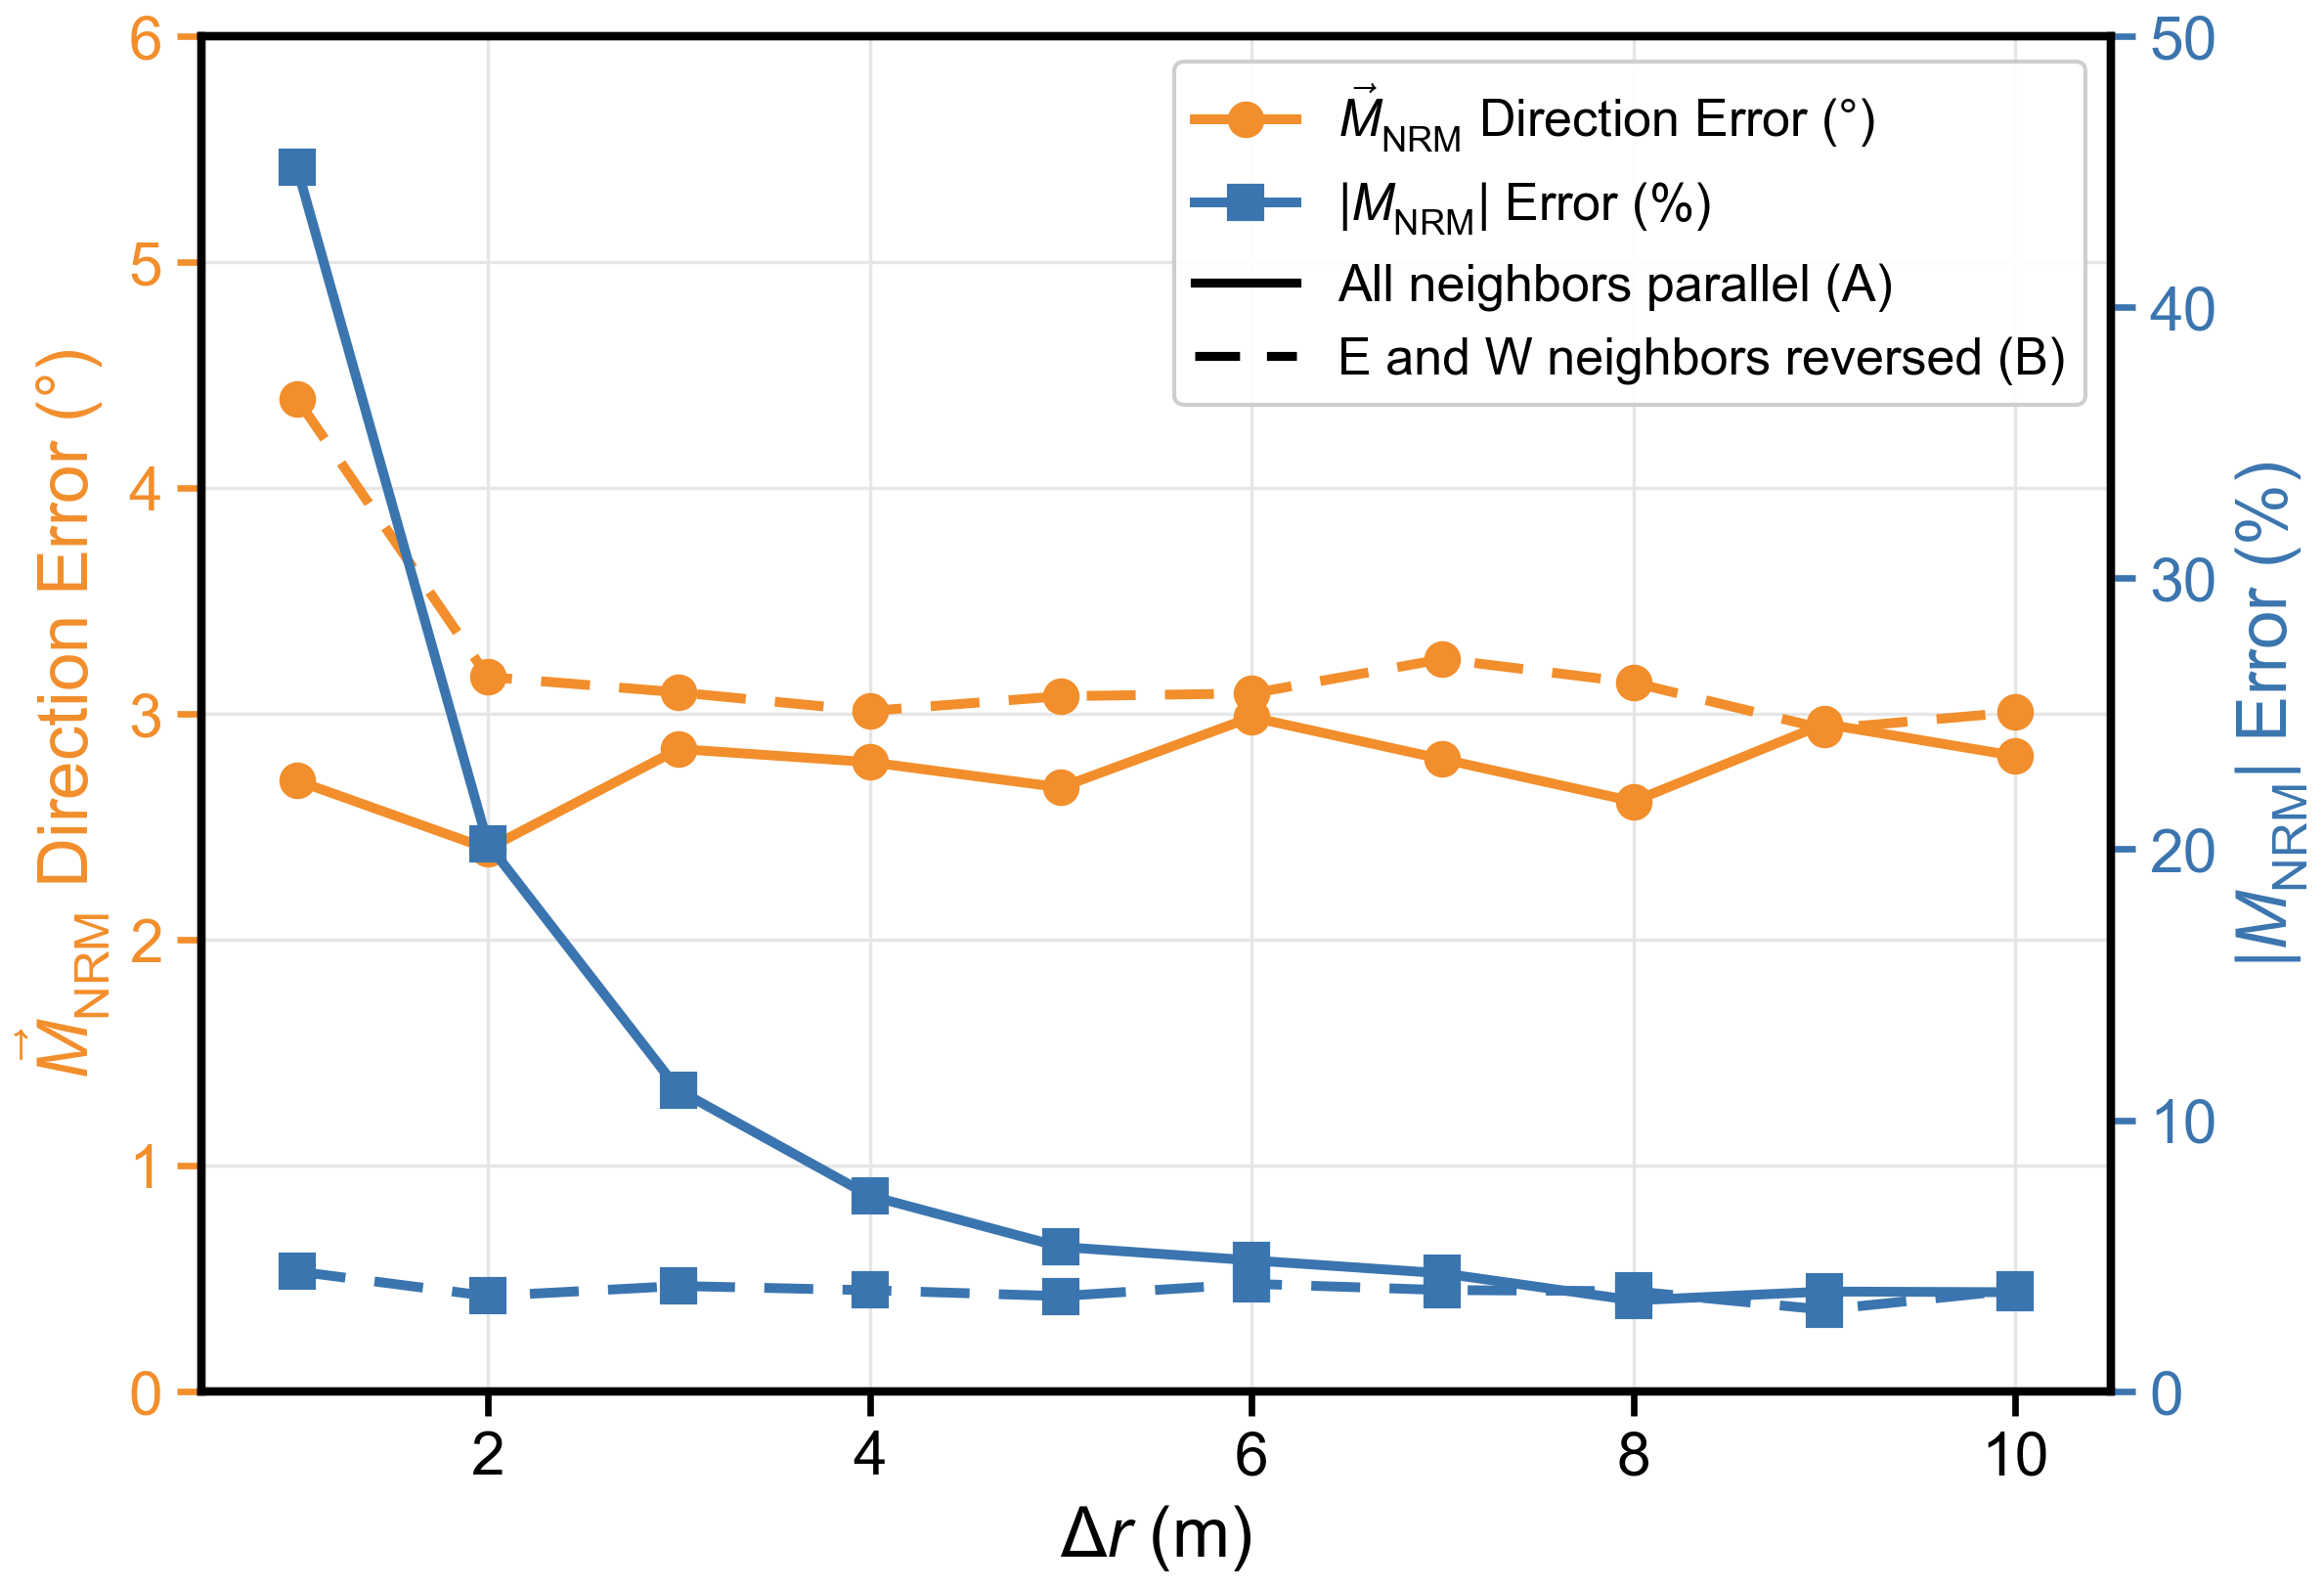


Section 4.3. Skate Park
      +45  …(configuration A), the intensity is biased high, with a mean signed intensity error of +45% at Δ r = 1 m, +20% at 2 m, and +11% at 3 m.
      +20  …is biased high, with a mean signed intensity error of +45% at Δ r = 1 m, +20% at 2 m, and +11% at 3 m.
      +11  …a mean signed intensity error of +45% at Δ r = 1 m, +20% at 2 m, and +11% at 3 m.
      2.4  The median direction error is 2.4–3.0° at every Δ r and is slightly lower than the isolated value at small Δ r …
      3.0  The median direction error is 2.4–3.0° at every Δ r and is slightly lower than the isolated value at small Δ r …
      5.3  For Δ r 5 m, the median intensity error is ≤5.3%, and at 8–10 m it is 3.3–3.7%, comparable to the isolated value of 3.7%.
    1.002  The residual RMS is 1.002 at Δ r = 1 m and 1.00 elsewhere, within the 0.008 scatter expected for 7197 …
      4.4  The median direction error is 4.4° at Δ r = 1 m and 2.9–3.2° from 2 to 10 m, which indicates that neighbors …
 

In [13]:
figure("fig06_skatepark_recovery", 600)
numbers("4.3")

## Section 4.4: three-layer wall (Table 4, Figure 7)

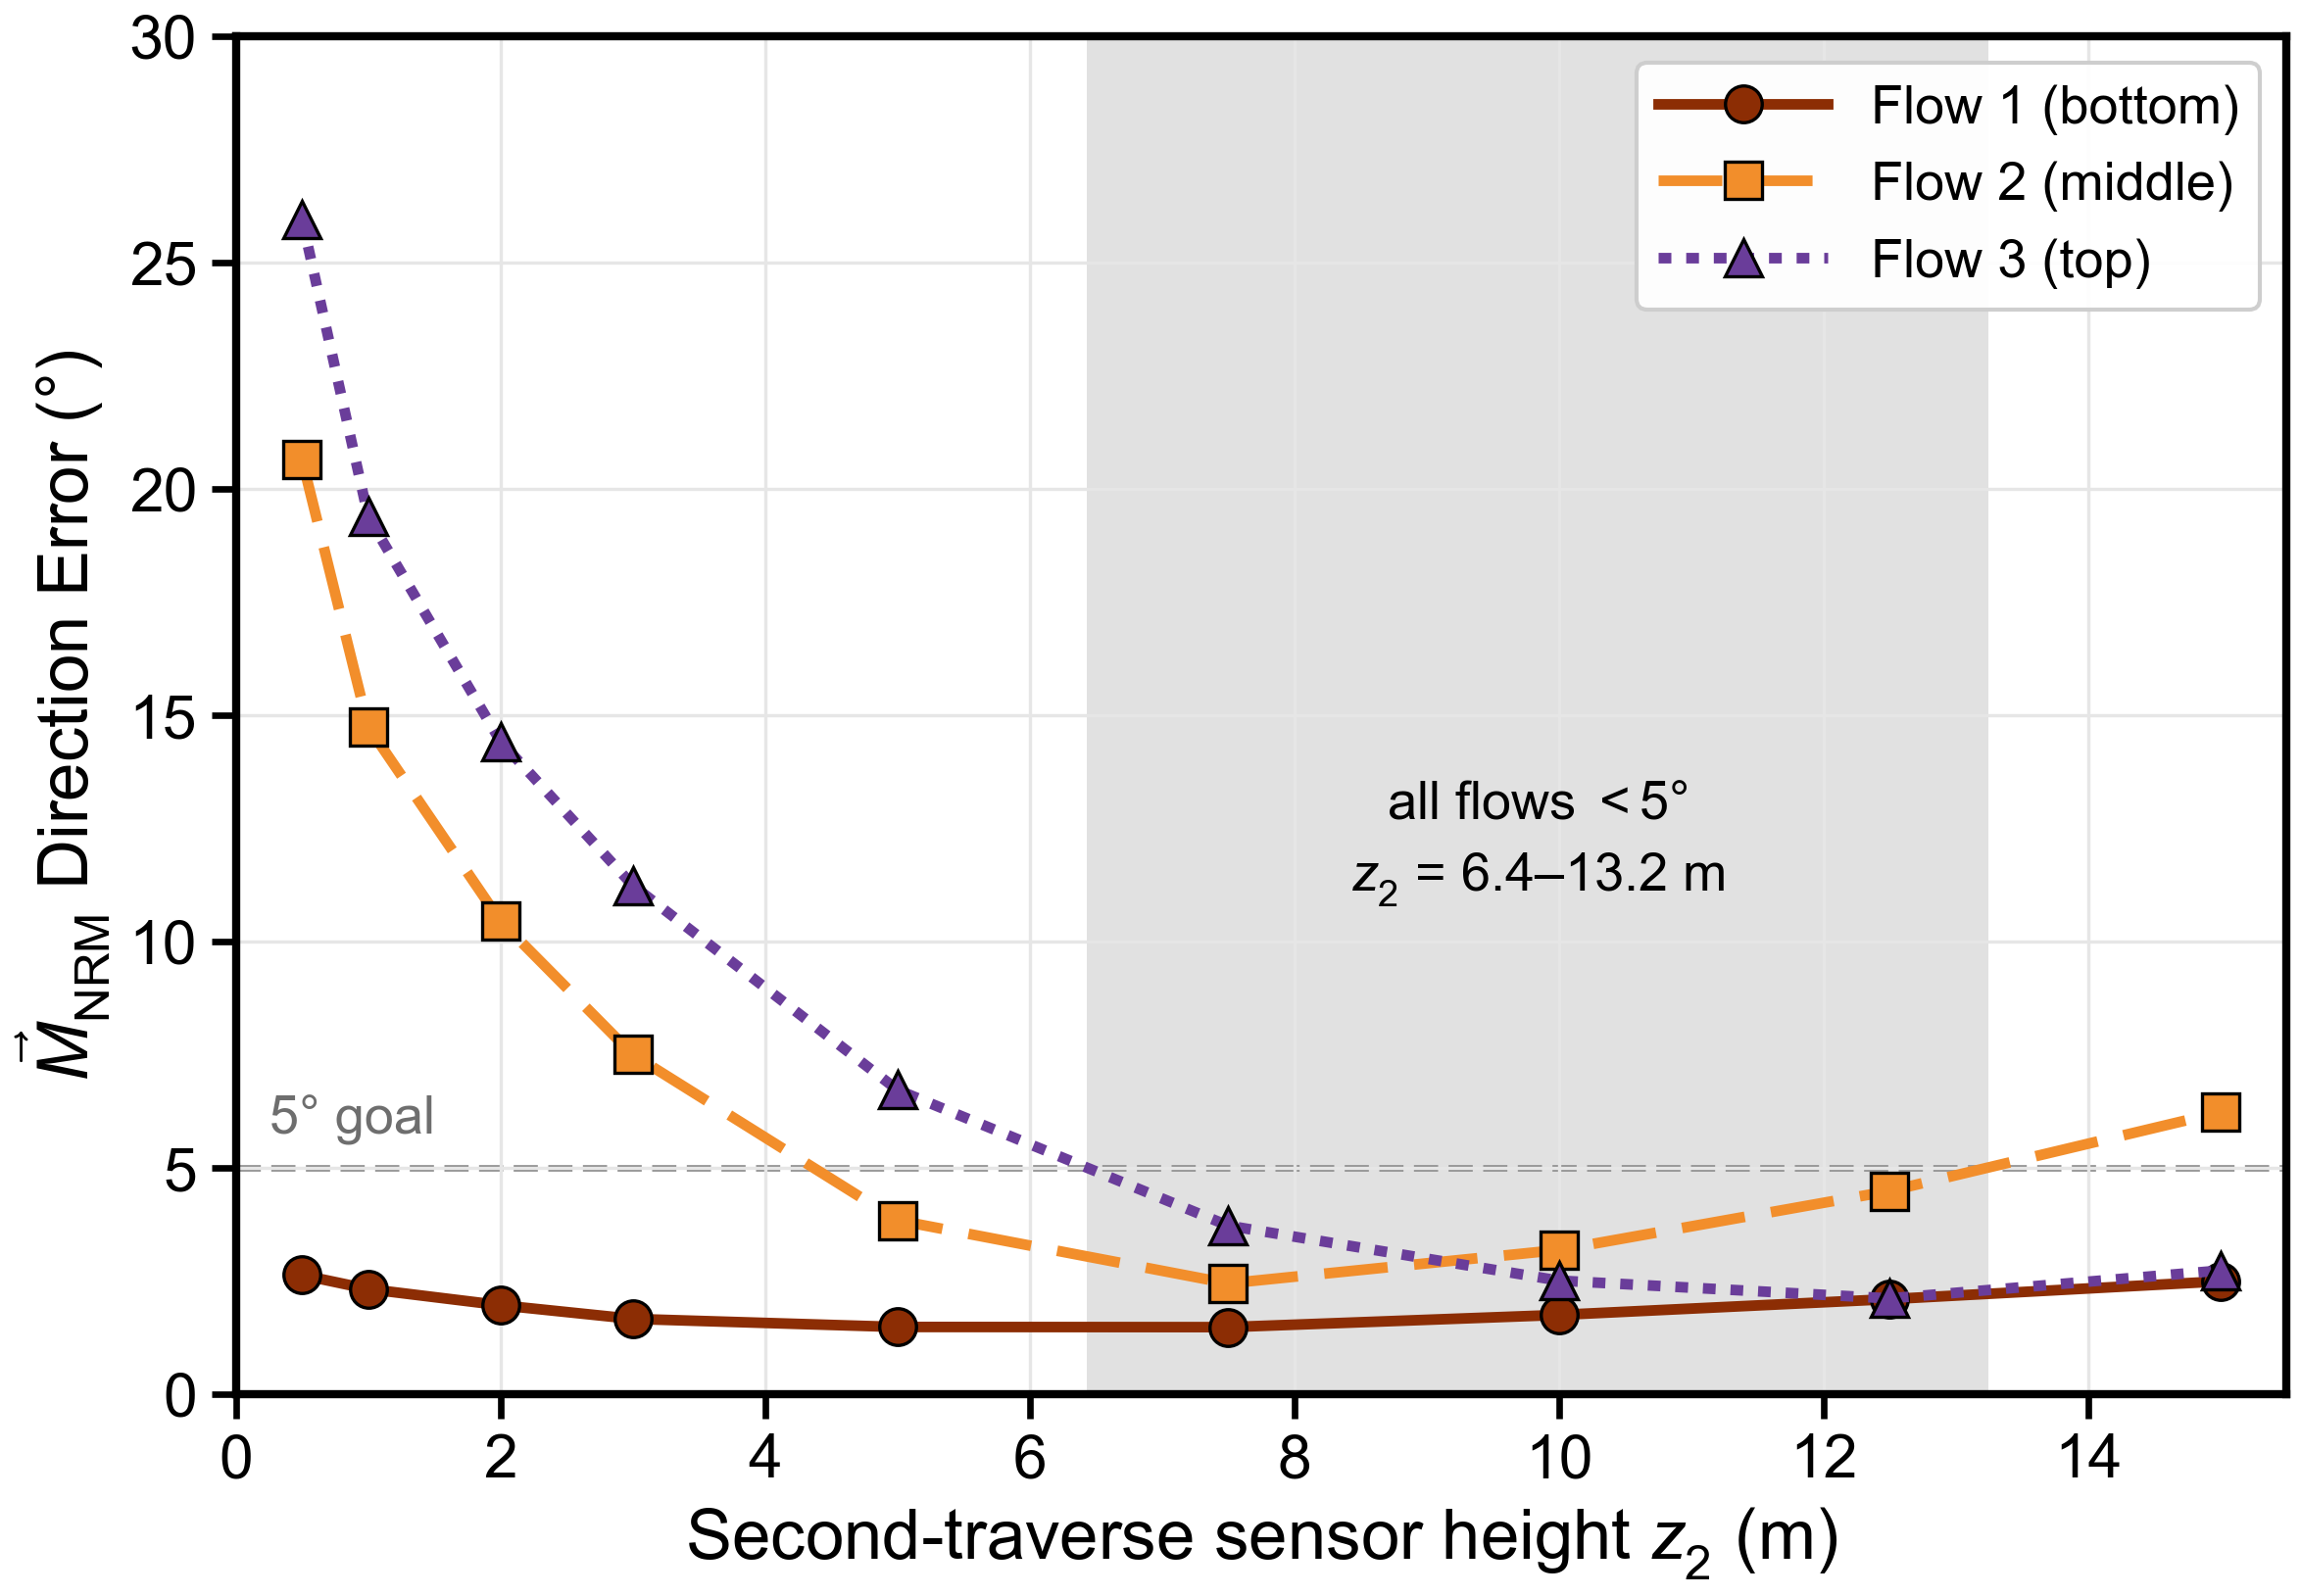


Section 4.4. Three-Layer Wall
     0.58  …traverse in front of the wall (|x| ≤ 50 m), the rms fields of the three flows are 0.58, 0.19, and 0.11 nT, compared with σ_B = 0.50 nT.
     0.19  …in front of the wall (|x| ≤ 50 m), the rms fields of the three flows are 0.58, 0.19, and 0.11 nT, compared with σ_B = 0.50 nT.
     0.11  …of the wall (|x| ≤ 50 m), the rms fields of the three flows are 0.58, 0.19, and 0.11 nT, compared with σ_B = 0.50 nT.
      3.7  Across 1000 inversions, the undamped solution recovers the lowest flow to 3.7 ± 2.0° (mean ±1-σ) and the middle and highest flows only to 28 ± 20° …
       28  …3.7 ± 2.0° (mean ±1-σ) and the middle and highest flows only to 28 ± 20° and 33 ± 20°, with mean intensities 18% and 29% too high because noise …
       33  …±1-σ) and the middle and highest flows only to 28 ± 20° and 33 ± 20°, with mean intensities 18% and 29% too high because noise inflates the magnitude …
       18  …middle and highest flows only to 28 ± 20° and 33 ± 20°, wi

In [14]:
figure("fig07_second_traverse_height", 600)
numbers("4.4")

## Sections 5 and 5.1: noise requirements (Figure 8)

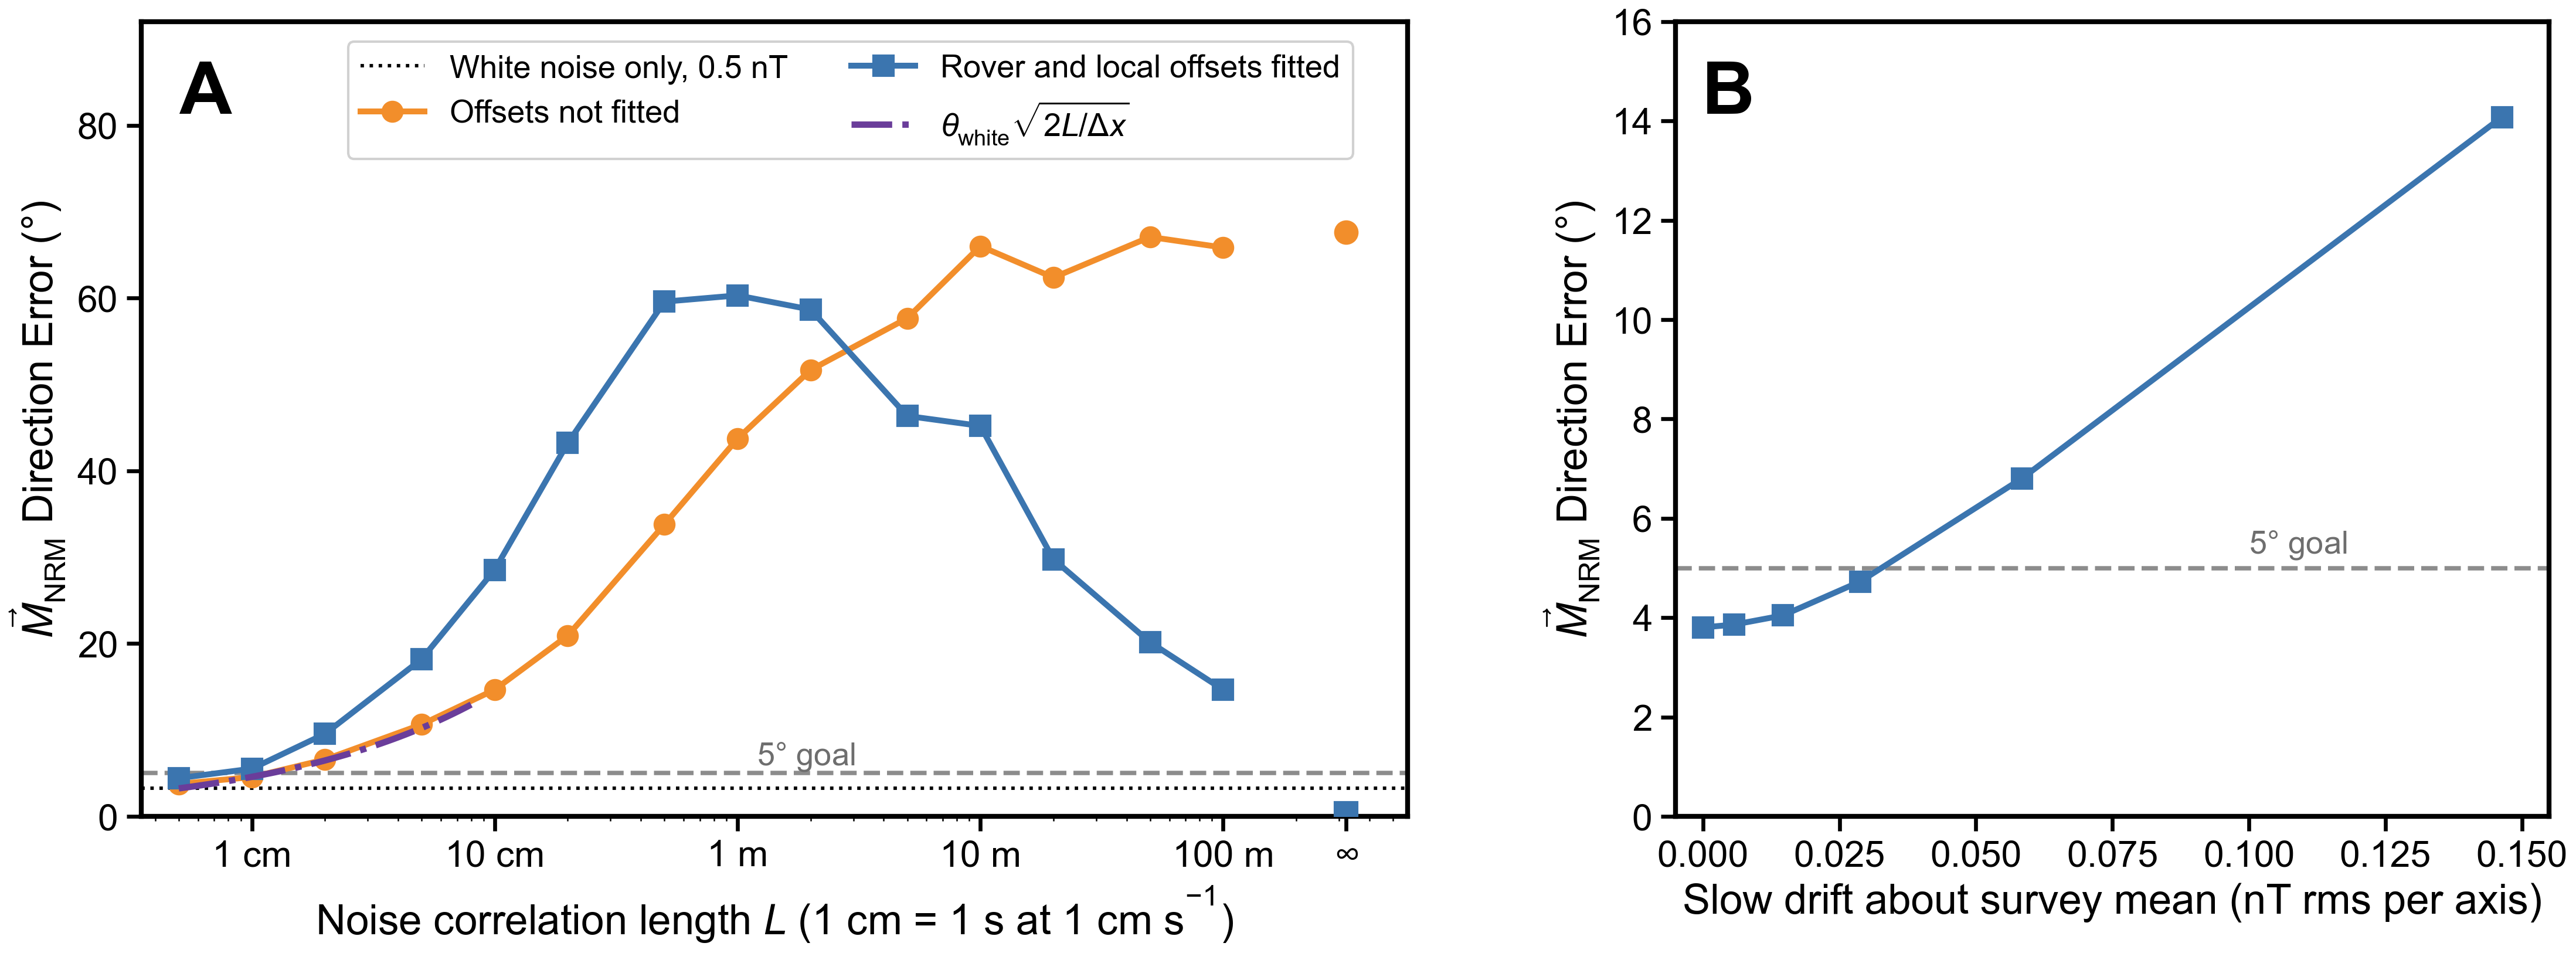


Section 5. Discussion
      9.8  …tolerance halved, the combined error is 3.4–5.7° for centered loops and 6.3–9.8° for loops 0.5 m off center (Section 5.3), with slow drift, the unknown …
      3.4  With every tolerance halved, the combined error is 3.4–5.7° for centered loops and 6.3–9.8° for loops 0.5 m off center …
      5.7  With every tolerance halved, the combined error is 3.4–5.7° for centered loops and 6.3–9.8° for loops 0.5 m off center (Section …
        5  …by tens of percent, and the combined runs at full, half, and quarter tolerance are biased high by 5–26%.
       26  …percent, and the combined runs at full, half, and quarter tolerance are biased high by 5–26%.

Section 5.1. Noise Requirements
      3.2  At a fixed ASD, sampling every 1, 2, 5, 10, or 25 cm gives the same mean direction error (3.2–3.3°; Table 3), because each coarser sample averages more of the …
      3.3  …a fixed ASD, sampling every 1, 2, 5, 10, or 25 cm gives the same mean direction error (3.2–3.3°; T

In [15]:
figure("fig08_noise_requirement")
numbers("5")
numbers("5.1")

## Sections 5.2 and 5.3: survey design and combined error budget (Table 5)

In [16]:
numbers("5.2")
numbers("5.3")


Section 5.2. Survey Design
       70  …with a second loop at ∼3 m standoff so that the site field can be fitted (70 min more at 1 cm s⁻¹).
      3.2  …tilt error is odd about the loop center, like a gradient, so tilts up to 0.3° leave the direction error at 3.2–4.5°.
      4.5  …loop center, like a gradient, so tilts up to 0.3° leave the direction error at 3.2–4.5°.
      3.0  …or 1.0 m sensor height, or with the loops 0.5 m off center, a tilt of 0.03° (0.16 nT) gives 3.0–8.0° and 0.1° gives 4.5–21°.
      8.0  …height, or with the loops 0.5 m off center, a tilt of 0.03° (0.16 nT) gives 3.0–8.0° and 0.1° gives 4.5–21°.
     0.16  …at 0.25 or 1.0 m sensor height, or with the loops 0.5 m off center, a tilt of 0.03° (0.16 nT) gives 3.0–8.0° and 0.1° gives 4.5–21°.
      4.5  …0.5 m off center, a tilt of 0.03° (0.16 nT) gives 3.0–8.0° and 0.1° gives 4.5–21°.
       21  …a tilt of 0.03° (0.16 nT) gives 3.0–8.0° and 0.1° gives 4.5–21°.
      1.1  …three site-field offsets in the three-layer

## Section 5.5: limitations

In [17]:
numbers("5.5")


Section 5.5. Limitations
     0.28  …passed 5° once the rms field of the background along the traverse exceeded 0.28 times that of the outcrop, and 10° at 0.77 times.
     0.77  …the traverse exceeded 0.28 times that of the outcrop, and 10° at 0.77 times.
       82  Across 82 pooled combinations of block size, intensity range, and direction scatter, the direction error passed …
      3.5  …to 0.3 nT m⁻¹ leaves the direction error of a vertical magnetization unchanged (3.5–3.7° with offsets fitted).
      3.7  …to 0.3 nT m⁻¹ leaves the direction error of a vertical magnetization unchanged (3.5–3.7° with offsets fitted).
        8  The drive-by has no such symmetry, and its error rises from 8° to 12° at 0.03 nT m⁻¹ and 27° at 0.1 nT m⁻¹, and fitting …
       12  The drive-by has no such symmetry, and its error rises from 8° to 12° at 0.03 nT m⁻¹ and 27° at 0.1 nT m⁻¹, and fitting the three gradient …
       27  …and its error rises from 8° to 12° at 0.03 nT m⁻¹ and 27° at 0.1 nT m⁻¹, an

## Summary

In [18]:
matched, total = count()
print(f"{matched} of {total} numbers in the paper reproduced")

374 of 374 numbers in the paper reproduced


# Rerunning the simulations

The stored results in `results/` come from the scripts below. Set `RERUN = True` in the first code cell (or start Jupyter
with `LUNAR_RERUN=1`) and run this cell to regenerate them. **This overwrites the files in `results/`.** Run time on
an Apple M-series laptop: about 3.5 to 4 hours, almost all of it `a09` (the per-script estimates in the list below sum
to 3 h 40 min; `a09` alone is about 3 h). The times were not re-measured for each release. `git diff results/` shows what
changed. When the cell finishes, `paper_numbers` is reloaded; run the Part 2 cells again to redraw the figures and
recheck the numbers from the new results.

In [19]:
SCRIPTS = [
    "notebook/part1_single_draw.py",                     # Part 1 single draw (--write)    < 1 min
    "engine/inversion_approach_comparison.py",           # Table 2                         1 min
    "analysis/a02_isolated_outcrop_paper_geometry.py",   # Section 4.2, Figure 5           15 min
    "analysis/a02b_detection_sweep_N1000.py",            # Figure 4                        1 min
    "analysis/a04_text_number_checks.py",                # Sections 4.2 and 4.4            1 min
    "analysis/a06_isolated_robustness.py",               # Table 3, Figure 8               1 min
    "engine/skatepark_1cm_dr_sweep.py",                  # Figure 6                        1 min
    "analysis/a08_skatepark_neighbor_directions.py",     # Section 4.3                     1 min
    "engine/three_layer_wall.py",                        # Table 4                         5 min
    "analysis/a03_three_layer_direction_vs_distance.py", # Section 4.4                     1 min
    "analysis/a07_three_layer_wall_extent.py",           # Section 4.4                     2 min
    "engine/scripts/elevated_traverse_height_sweep.py",  # Figure 7                        5 min
    "analysis/a05_background_and_correlated_noise.py",   # Sections 3.3, 5.1 and 5.5       5 min
    "analysis/a09_systematics.py",                       # Sections 4.2, 5.1-5.5, Table 5  3 hr
]

if RERUN:
    for script in SCRIPTS:
        args = ["--write"] if script.endswith("part1_single_draw.py") else []
        subprocess.run([sys.executable, os.path.join(ROOT, script), *args], cwd=ROOT, check=True)

    # Refresh the values loaded from results/ before running Part 2 again.
    import importlib
    import paper_numbers
    importlib.reload(paper_numbers)
    numbers, count, J = paper_numbers.numbers, paper_numbers.count, paper_numbers.J
else:
    print("RERUN = False: nothing was rerun; the numbers above come from the stored results in results/.")

RERUN = False: nothing was rerun; the numbers above come from the stored results in results/.
